# Experiment 7: Sentiment Analysis on IMDB Movie Reviews

This notebook implements and compares four sentiment analysis models on the **IMDB 50K Movie Reviews Dataset** (`IMDB-Dataset.csv`):
1. **Logistic Regression** (TF-IDF + Linear Classifier)
2. **LSTM** (Bidirectional Long Short-Term Memory network in PyTorch)
3. **Vanilla Transformer** (Multi-Head Self-Attention `TransformerEncoder` in PyTorch)
4. **Pretrained BERT** (`textattack/bert-base-uncased-imdb` via Hugging Face `transformers`)

All models are evaluated on the **same stratified test set** using **Accuracy**, **Precision**, **Recall**, **F1-Score**, and **Confusion Matrix** analysis.

## 1. Load & Preprocess the IMDB Dataset

We load `IMDB-Dataset.csv` (50,000 reviews), strip HTML tags (`<br />`), normalize whitespace, and create a stratified train/test split (`8,000` training reviews and `1,000` test reviews) so all four models — including CPU-based deep learning and BERT inference — are evaluated fairly on the exact same test set.

In [1]:
import re
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load IMDB Dataset
df = pd.read_csv("IMDB-Dataset.csv")
print("Full dataset shape:", df.shape)
print("Class distribution:\n", df["sentiment"].value_counts().to_string())

def clean_text(text):
    text = re.sub(r"<br\s*/?>", " ", str(text))
    text = re.sub(r"[^a-zA-Z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

df["clean_review"] = df["review"].apply(clean_text)
df["label"] = (df["sentiment"] == "positive").astype(int)

# Stratified subset for fair comparison across all 4 models on CPU
df_sub, _ = train_test_split(
    df, train_size=9000, stratify=df["label"], random_state=SEED
)
X_train, X_test, y_train, y_test = train_test_split(
    df_sub["clean_review"].tolist(),
    df_sub["label"].values,
    test_size=1000,
    stratify=df_sub["label"].values,
    random_state=SEED,
)
print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")

results = {}
conf_matrices = {}

def evaluate_model(name, y_true, y_pred, elapsed_sec):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "Time (s)": elapsed_sec,
    }
    conf_matrices[name] = cm
    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f} | Time: {elapsed_sec:.2f}s")
    print(classification_report(y_true, y_pred, target_names=["Negative", "Positive"], digits=4))

Using device: cpu
Full dataset shape: (50000, 2)
Class distribution:
 sentiment
positive    25000
negative    25000
Train size: 8000 | Test size: 1000


## 2. Model 1 — Logistic Regression (TF-IDF)

We vectorize the cleaned reviews using unigram + bigram TF-IDF features (`max_features=20,000`) and train a `LogisticRegression` classifier.

In [2]:
t0 = time.time()
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), stop_words="english")
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

lr_model = LogisticRegression(max_iter=1000, C=1.0, random_state=SEED)
lr_model.fit(X_train_tfidf, y_train)
lr_preds = lr_model.predict(X_test_tfidf)
lr_time = time.time() - t0

evaluate_model("Logistic Regression", y_test, lr_preds, lr_time)

=== Logistic Regression ===
Accuracy: 0.8710 | Precision: 0.8616 | Recall: 0.8840 | F1: 0.8727 | Time: 1.76s
              precision    recall  f1-score   support

    Negative     0.8809    0.8580    0.8693       500
    Positive     0.8616    0.8840    0.8727       500

    accuracy                         0.8710      1000
   macro avg     0.8713    0.8710    0.8710      1000
weighted avg     0.8713    0.8710    0.8710      1000



## 3. Shared Tokenization & DataLoaders for Neural Models (LSTM & Vanilla Transformer)

We build a vocabulary of the top `10,000` words from the training split and pad/truncate each review to `max_len = 150` tokens.

In [3]:
from collections import Counter

MAX_VOCAB = 10000
MAX_LEN = 150
BATCH_SIZE = 64

counter = Counter(tok for text in X_train for tok in text.split())
vocab = {"<PAD>": 0, "<UNK>": 1}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode_texts(texts, vocab, max_len=MAX_LEN):
    arr = np.zeros((len(texts), max_len), dtype=np.int64)
    for i, text in enumerate(texts):
        tokens = text.split()[:max_len]
        for j, tok in enumerate(tokens):
            arr[i, j] = vocab.get(tok, 1)
    return torch.tensor(arr, dtype=torch.long)

X_train_seq = encode_texts(X_train, vocab, MAX_LEN)
X_test_seq = encode_texts(X_test, vocab, MAX_LEN)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_seq, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_seq, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

print(f"Vocabulary size: {len(vocab)} | Sequence tensor shape: {X_train_seq.shape}")

def train_and_eval_torch(model, train_loader, test_loader, epochs=5, lr=1e-3):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    t_start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * xb.size(0)
        print(f"Epoch {epoch}/{epochs} | Train Loss: {total_loss / len(train_loader.dataset):.4f}")

    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in test_loader:
            logits = model(xb.to(device))
            probs = torch.sigmoid(logits)
            preds.extend((probs >= 0.5).long().cpu().numpy())
    elapsed = time.time() - t_start
    return np.array(preds), elapsed

Vocabulary size: 10000 | Sequence tensor shape: torch.Size([8000, 150])


## 4. Model 2 — Bidirectional LSTM

We train a 2-layer Bidirectional LSTM with `embed_dim=64`, `hidden_dim=64`, and dropout regularization.

In [4]:
class LSTMSentiment(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim, num_layers=2,
            batch_first=True, bidirectional=True, dropout=dropout
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        emb = self.dropout(self.embedding(x))
        _, (hidden, _) = self.lstm(emb)
        # Concatenate final forward and backward hidden states
        cat = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(cat)).squeeze(1)

lstm_model = LSTMSentiment(len(vocab))
lstm_preds, lstm_time = train_and_eval_torch(lstm_model, train_loader, test_loader, epochs=5, lr=1e-3)
evaluate_model("LSTM", y_test, lstm_preds, lstm_time)

Epoch 1/5 | Train Loss: 0.6900
Epoch 2/5 | Train Loss: 0.6647
Epoch 3/5 | Train Loss: 0.6131
Epoch 4/5 | Train Loss: 0.5612
Epoch 5/5 | Train Loss: 0.5169
=== LSTM ===
Accuracy: 0.7790 | Precision: 0.7460 | Recall: 0.8460 | F1: 0.7929 | Time: 84.98s
              precision    recall  f1-score   support

    Negative     0.8222    0.7120    0.7631       500
    Positive     0.7460    0.8460    0.7929       500

    accuracy                         0.7790      1000
   macro avg     0.7841    0.7790    0.7780      1000
weighted avg     0.7841    0.7790    0.7780      1000



## 5. Model 3 — Vanilla Transformer Encoder

We build a Vanilla Transformer classifier from scratch using token embeddings, sinusoidal positional encoding, a 2-layer `nn.TransformerEncoder` (`d_model=64`, `nhead=4`), masked mean pooling, and a linear classification head.

In [5]:
import math

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class VanillaTransformerSentiment(nn.Module):
    def __init__(self, vocab_size, d_model=64, nhead=4, num_layers=2, dim_ff=128, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos_enc = PositionalEncoding(d_model, max_len=MAX_LEN)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        pad_mask = (x == 0)
        h = self.pos_enc(self.embedding(x) * math.sqrt(self.embedding.embedding_dim))
        h = self.encoder(h, src_key_padding_mask=pad_mask)
        # Masked mean pooling over non-padding tokens
        non_pad = (~pad_mask).unsqueeze(-1).float()
        pooled = (h * non_pad).sum(dim=1) / torch.clamp(non_pad.sum(dim=1), min=1.0)
        return self.fc(self.dropout(pooled)).squeeze(1)

transformer_model = VanillaTransformerSentiment(len(vocab))
tf_preds, tf_time = train_and_eval_torch(transformer_model, train_loader, test_loader, epochs=5, lr=1e-3)
evaluate_model("Vanilla Transformer", y_test, tf_preds, tf_time)

Epoch 1/5 | Train Loss: 0.6276
Epoch 2/5 | Train Loss: 0.4887
Epoch 3/5 | Train Loss: 0.4090
Epoch 4/5 | Train Loss: 0.3500
Epoch 5/5 | Train Loss: 0.2903
=== Vanilla Transformer ===
Accuracy: 0.7880 | Precision: 0.7717 | Recall: 0.8180 | F1: 0.7942 | Time: 89.49s
              precision    recall  f1-score   support

    Negative     0.8064    0.7580    0.7814       500
    Positive     0.7717    0.8180    0.7942       500

    accuracy                         0.7880      1000
   macro avg     0.7890    0.7880    0.7878      1000
weighted avg     0.7890    0.7880    0.7878      1000



## 6. Model 4 — Pretrained BERT (`textattack/bert-base-uncased-imdb`)

We load the pretrained `bert-base-uncased` model fine-tuned on IMDB (`textattack/bert-base-uncased-imdb`) and run batched inference on the same `1,000` test reviews (`max_length=128`).

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "textattack/bert-base-uncased-imdb"
bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device)
bert_model.eval()

t0 = time.time()
bert_preds = []
batch_size_bert = 32

with torch.no_grad():
    for i in range(0, len(X_test), batch_size_bert):
        batch_texts = X_test[i:i + batch_size_bert]
        enc = bert_tokenizer(
            batch_texts, padding=True, truncation=True, max_length=128, return_tensors="pt"
        ).to(device)
        logits = bert_model(**enc).logits
        bert_preds.extend(torch.argmax(logits, dim=-1).cpu().numpy())

bert_time = time.time() - t0
bert_preds = np.array(bert_preds)
evaluate_model("Pretrained BERT", y_test, bert_preds, bert_time)

=== Pretrained BERT ===
Accuracy: 0.9370 | Precision: 0.9344 | Recall: 0.9400 | F1: 0.9372 | Time: 33.87s
              precision    recall  f1-score   support

    Negative     0.9396    0.9340    0.9368       500
    Positive     0.9344    0.9400    0.9372       500

    accuracy                         0.9370      1000
   macro avg     0.9370    0.9370    0.9370      1000
weighted avg     0.9370    0.9370    0.9370      1000



## 7. Comparative Analysis & Confusion Matrices

We compare all four models side-by-side on **Accuracy**, **Precision**, **Recall**, **F1-Score**, and **Confusion Matrices**.

=== Comparative Performance Summary (Same 1,000-Review Test Set) ===
                     Accuracy  Precision  Recall  F1-Score  Time (s)
Logistic Regression     0.871     0.8616   0.884    0.8727    1.7647
LSTM                    0.779     0.7460   0.846    0.7929   84.9838
Vanilla Transformer     0.788     0.7717   0.818    0.7942   89.4883
Pretrained BERT         0.937     0.9344   0.940    0.9372   33.8679


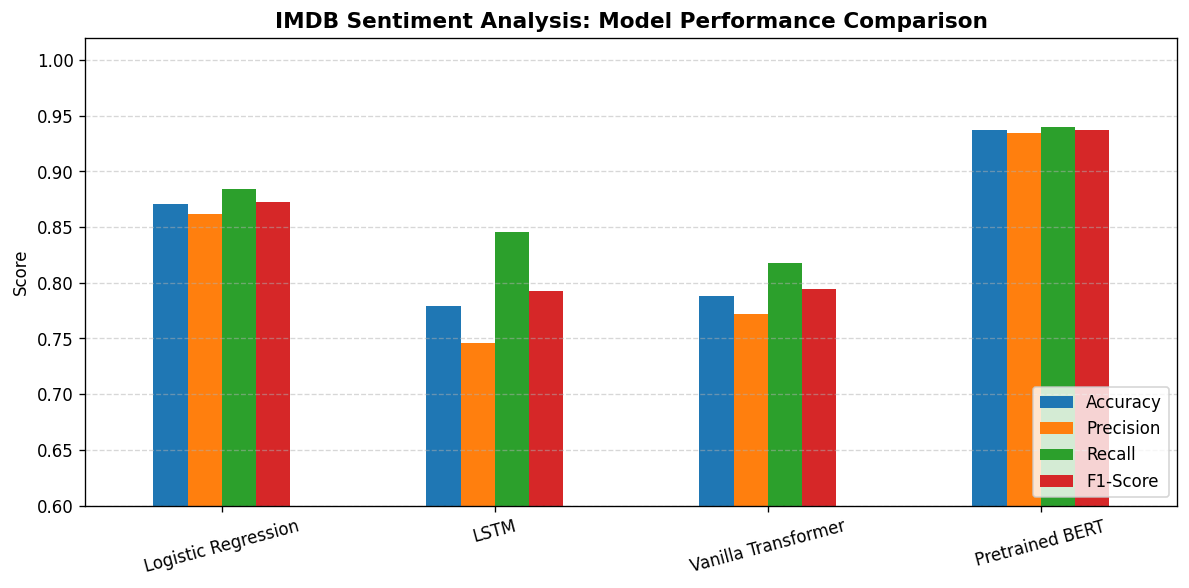

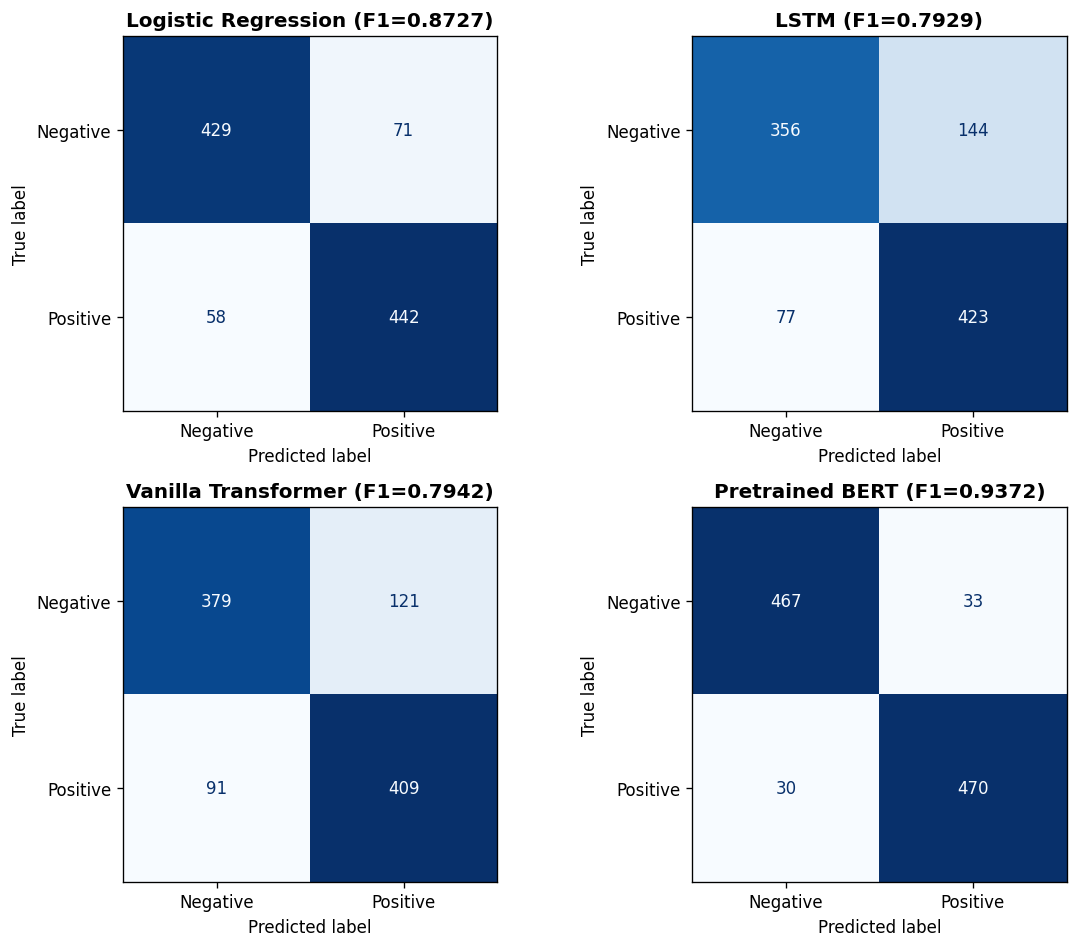

In [7]:
comp_df = pd.DataFrame(results).T
comp_df = comp_df[["Accuracy", "Precision", "Recall", "F1-Score", "Time (s)"]]
print("=== Comparative Performance Summary (Same 1,000-Review Test Set) ===")
print(comp_df.round(4).to_string())

# Plot 1: Metric Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10, 5))
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score"]
comp_df[metrics_to_plot].plot(kind="bar", ax=ax, ylim=(0.6, 1.02), rot=15)
ax.set_title("IMDB Sentiment Analysis: Model Performance Comparison", fontsize=13, fontweight="bold")
ax.set_ylabel("Score")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Plot 2: Confusion Matrices for all 4 models
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, cm) in zip(axes.flatten(), conf_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name} (F1={results[name]['F1-Score']:.4f})", fontweight="bold")
plt.tight_layout()
plt.show()